In [2]:
import os
os.getcwd()

'C:\\Users\\madha'

In [3]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

In [4]:
data=pd.read_excel("data.xlsx")

In [5]:
country_code=pd.read_excel("Country-Code.xlsx")

In [56]:
 data.shape

(9551, 19)

In [6]:
data.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Price range,Aggregate rating,Rating color,Rating text,Votes
0,7402935,Skye,94,Jakarta,"Menara BCA, Lantai 56, Jl. MH. Thamrin, Thamri...","Grand Indonesia Mall, Thamrin","Grand Indonesia Mall, Thamrin, Jakarta",106.821999,-6.196778,"Italian, Continental",800000,Indonesian Rupiah(IDR),No,No,3,4.1,Green,Very Good,1498
1,7410290,Satoo - Hotel Shangri-La,94,Jakarta,"Hotel Shangri-La, Jl. Jend. Sudirman","Hotel Shangri-La, Sudirman","Hotel Shangri-La, Sudirman, Jakarta",106.818961,-6.203292,"Asian, Indonesian, Western",800000,Indonesian Rupiah(IDR),No,No,3,4.6,Dark Green,Excellent,873
2,7420899,Sushi Masa,94,Jakarta,"Jl. Tuna Raya No. 5, Penjaringan",Penjaringan,"Penjaringan, Jakarta",106.800144,-6.101298,"Sushi, Japanese",500000,Indonesian Rupiah(IDR),No,No,3,4.9,Dark Green,Excellent,605
3,7421967,3 Wise Monkeys,94,Jakarta,"Jl. Suryo No. 26, Senopati, Jakarta",Senopati,"Senopati, Jakarta",106.813400,-6.235241,Japanese,450000,Indonesian Rupiah(IDR),No,No,3,4.2,Green,Very Good,395
4,7422489,Avec Moi Restaurant and Bar,94,Jakarta,"Gedung PIC, Jl. Teluk Betung 43, Thamrin, Jakarta",Thamrin,"Thamrin, Jakarta",106.821023,-6.196270,"French, Western",350000,Indonesian Rupiah(IDR),No,No,3,4.3,Green,Very Good,243


In [7]:
country_code.head()

,Country Code,Country
0,1,India
1,14,Australia
2,30,Brazil
3,37,Canada
4,94,Indonesia


In [55]:
data.shape
data.columns


Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Price range', 'Aggregate rating',
       'Rating color', 'Rating text', 'Votes'],
      dtype='object')

In [9]:
# str of data

data.shape

data.info()

data.isnull().sum()

print(data.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9550 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Price range           9551 non-null   int64  
 15  Aggregate rating     

#### Count missing values

In [10]:
data.isnull().sum()

Restaurant ID           0
Restaurant Name         1
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                9
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64

In [11]:
data.isnull().sum()/len(data)*100

Restaurant ID           0.000000
Restaurant Name         0.010470
Country Code            0.000000
City                    0.000000
Address                 0.000000
Locality                0.000000
Locality Verbose        0.000000
Longitude               0.000000
Latitude                0.000000
Cuisines                0.094231
Average Cost for two    0.000000
Currency                0.000000
Has Table booking       0.000000
Has Online delivery     0.000000
Price range             0.000000
Aggregate rating        0.000000
Rating color            0.000000
Rating text             0.000000
Votes                   0.000000
dtype: float64

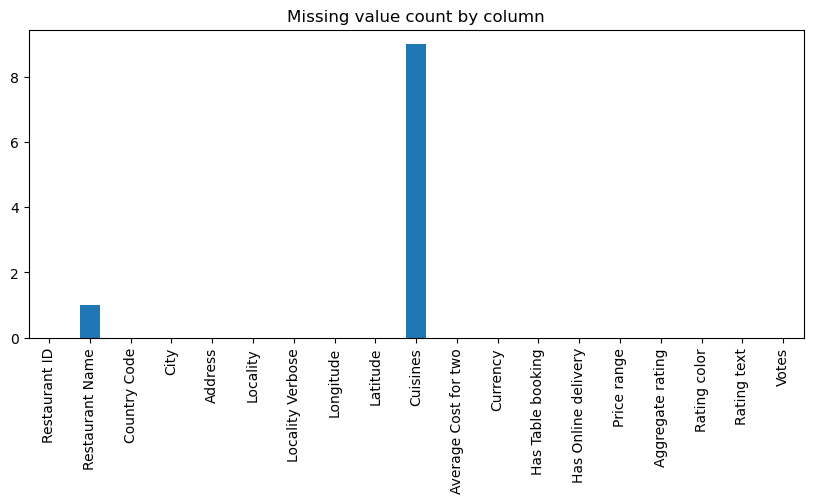

In [12]:
data.isnull().sum().plot(kind='bar',figsize=(10,4))
plt.title("Missing value count by column")
plt.show()

In [13]:
data.duplicated().sum()

np.int64(0)

In [14]:
data[data.duplicated()]

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Price range,Aggregate rating,Rating color,Rating text,Votes


In [15]:
data=data.drop_duplicates()

print(data.duplicated().sum())

0


#### Report - “Only a negligible percentage of missing values (<0.1%) was observed in Restaurant Name and Cuisines columns. Rather than removing these records, missing values were retained for initial analysis and treated selectively based on business relevance during EDA.”

#### Merge Country Name

In [16]:
data_merged=pd.merge(
    data,country_code,
    on='Country Code',
    how='left')

In [17]:
data_merged.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Price range,Aggregate rating,Rating color,Rating text,Votes,Country
0,7402935,Skye,94,Jakarta,"Menara BCA, Lantai 56, Jl. MH. Thamrin, Thamri...","Grand Indonesia Mall, Thamrin","Grand Indonesia Mall, Thamrin, Jakarta",106.821999,-6.196778,"Italian, Continental",800000,Indonesian Rupiah(IDR),No,No,3,4.1,Green,Very Good,1498,Indonesia
1,7410290,Satoo - Hotel Shangri-La,94,Jakarta,"Hotel Shangri-La, Jl. Jend. Sudirman","Hotel Shangri-La, Sudirman","Hotel Shangri-La, Sudirman, Jakarta",106.818961,-6.203292,"Asian, Indonesian, Western",800000,Indonesian Rupiah(IDR),No,No,3,4.6,Dark Green,Excellent,873,Indonesia
2,7420899,Sushi Masa,94,Jakarta,"Jl. Tuna Raya No. 5, Penjaringan",Penjaringan,"Penjaringan, Jakarta",106.800144,-6.101298,"Sushi, Japanese",500000,Indonesian Rupiah(IDR),No,No,3,4.9,Dark Green,Excellent,605,Indonesia
3,7421967,3 Wise Monkeys,94,Jakarta,"Jl. Suryo No. 26, Senopati, Jakarta",Senopati,"Senopati, Jakarta",106.813400,-6.235241,Japanese,450000,Indonesian Rupiah(IDR),No,No,3,4.2,Green,Very Good,395,Indonesia
4,7422489,Avec Moi Restaurant and Bar,94,Jakarta,"Gedung PIC, Jl. Teluk Betung 43, Thamrin, Jakarta",Thamrin,"Thamrin, Jakarta",106.821023,-6.196270,"French, Western",350000,Indonesian Rupiah(IDR),No,No,3,4.3,Green,Very Good,243,Indonesia


In [18]:
data_merged[['Country Code', 'Country']].head()

,Country Code,Country
0,94,Indonesia
1,94,Indonesia
2,94,Indonesia
3,94,Indonesia
4,94,Indonesia


#### Count Restaurants By Country

In [19]:
country_dist=data_merged['Country'].value_counts()
country_dist

Country
India             8652
United States      434
United Kingdom      80
UAE                 60
Brazil              60
South Africa        60
New Zealand         40
Turkey              34
Australia           24
Phillipines         22
Indonesia           21
Singapore           20
Qatar               20
Sri Lanka           20
Canada               4
Name: count, dtype: int64

#### Visualize Country Distribution (Top 10 Countries)

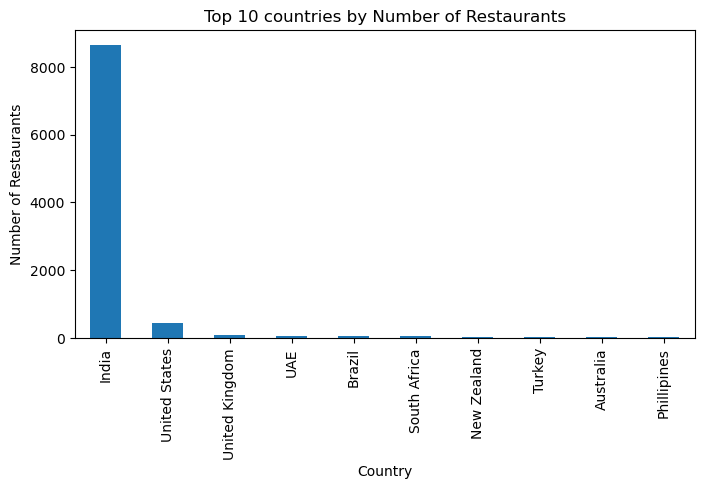

In [20]:
country_dist.head(10).plot(
    kind='bar',
    figsize=(8,4),
    title='Top 10 countries by Number of Restaurants'
)
plt.ylabel("Number of Restaurants")
plt.show()

#### Citywise Restaurant Distribution 

In [21]:
city_dist=data_merged['City'].value_counts()
city_dist.head(10)

City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Ahmedabad         21
Amritsar          21
Bhubaneshwar      21
Guwahati          21
Lucknow           21
Name: count, dtype: int64

#### City with max restaurants 

In [22]:
city_dist.idxmax(),city_dist.max()

('New Delhi', 5473)

#### City with min restaurants

In [23]:
city_dist.idxmin(),city_dist.min()

('Bandung', 1)

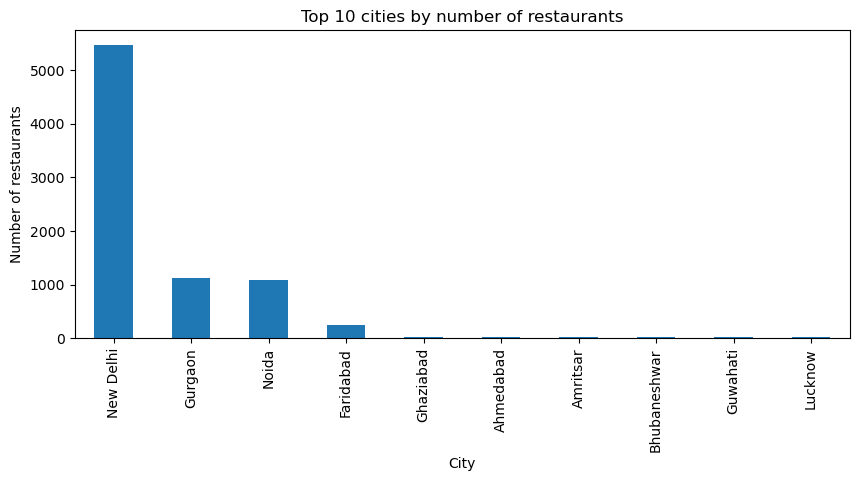

In [24]:
city_dist.head(10).plot(
    kind='bar',
    figsize=(10,4),
    title='Top 10 cities by number of restaurants'
)
plt.ylabel('Number of restaurants')
plt.show()

#### Report - “Geographical analysis shows that restaurant presence is highly concentrated in specific countries and cities. A small number of cities account for a disproportionately large share of restaurants, while several cities have minimal representation, highlighting potential areas for market expansion.”

#### Group by Restaurant Name and count countries

In [25]:
franchise_presence = (
    data_merged.groupby('Restaurant Name')['Country'].nunique().sort_values(ascending=False)
)

#### Top franchise by national presence 

In [26]:
franchise_presence.head(10)

Restaurant Name
Hard Rock Cafe         3
Indian Coffee House    2
Ichiban                2
Gazebo                 2
Jamie's Italian        2
Din Tai Fung           2
Barbeque Nation        2
Gymkhana               2
Chili's Grill & Bar    2
Applebee's             2
Name: Country, dtype: int64

#### Franchise with most national presence 

In [27]:
top_franchise = franchise_presence.idxmax()
top_franchise_countries = franchise_presence.max()
top_franchise,top_franchise_countries

('Hard Rock Cafe', 3)

#### Ratio : Table booking Vs No Table booking

In [28]:
table_booking_counts = data_merged['Has Table booking'].value_counts()
table_booking_counts

Has Table booking
No     8393
Yes    1158
Name: count, dtype: int64

In [29]:
table_booking_ratio = table_booking_counts/table_booking_counts.sum()
table_booking_ratio

Has Table booking
No     0.878756
Yes    0.121244
Name: count, dtype: float64

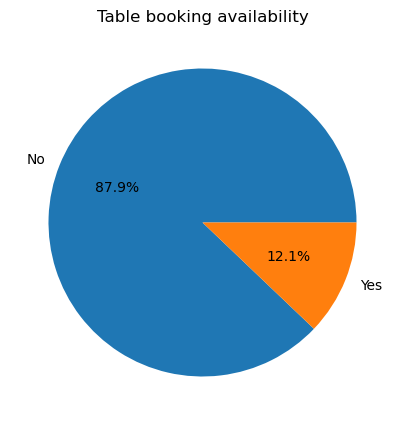

In [30]:
table_booking_counts.plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(5,5),
    title = 'Table booking availability'
)
plt.ylabel('')
plt.show()

In [31]:
online_delivery_counts = data_merged['Has Online delivery'].value_counts()
online_delivery_counts

Has Online delivery
No     7100
Yes    2451
Name: count, dtype: int64

In [32]:
online_delivery_percentage = (
    online_delivery_counts/online_delivery_counts.sum()
)*100
online_delivery_percentage

Has Online delivery
No     74.337766
Yes    25.662234
Name: count, dtype: float64

##### Interpretation:

Approximately 25% of restaurants provide online delivery, reflecting the level of digital adoption in the market.

#### Aggregate Votes By Delivery Options 

In [33]:
votes_by_delivery = (
    data_merged.groupby('Has Online delivery')['Votes'].sum()
)
votes_by_delivery

Has Online delivery
No     980731
Yes    517914
Name: Votes, dtype: int64

#### Difference in Votes

In [34]:
vote_difference = votes_by_delivery.max() - votes_by_delivery.min()
vote_difference

462817

In [35]:
res_count=data_merged.groupby('Has Online delivery')['Restaurant ID'].nunique()
res_count

Has Online delivery
No     7100
Yes    2451
Name: Restaurant ID, dtype: int64

In [36]:
avg_vote= votes_by_delivery/res_count
avg_vote

Has Online delivery
No     138.131127
Yes    211.307222
dtype: float64

##### Interpretation:

Restaurants offering online delivery tend to receive higher customer engagement, as reflected by a higher number of votes.

#### Top 10 cuisines served across cities 

In [37]:
# split cuisines into individual value 

cuisine_series = (
    data_merged['Cuisines'].dropna().str.split(',').explode()
)

In [38]:
# top 10 cuisines overall 
top_10_cuisines = cuisine_series.value_counts().head(10)
top_10_cuisines

Cuisines
North Indian     2992
 Chinese         1880
 Fast Food       1314
 North Indian     968
Chinese           855
 Mughlai          780
Fast Food         672
Bakery            621
Cafe              617
 Italian          530
Name: count, dtype: int64

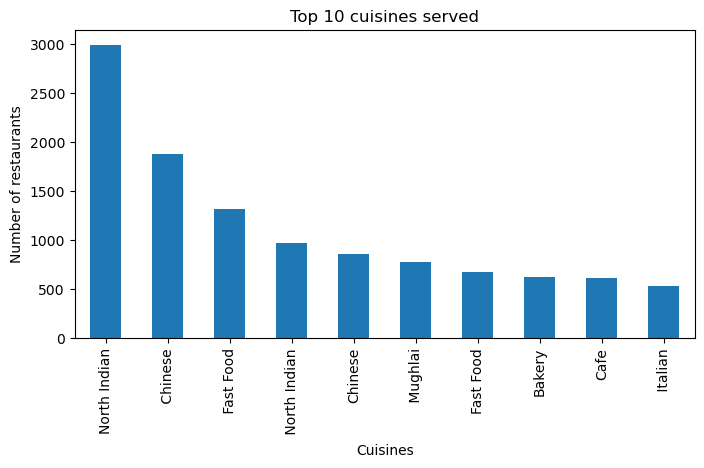

In [39]:
top_10_cuisines.plot(
    kind='bar',
    figsize=(8,4),
    title = 'Top 10 cuisines served'
)
plt.ylabel("Number of restaurants")
plt.show()

#### Cuisine count per day and most served cuisine per city

In [40]:
# Number of cuisine per restaurant 

data_merged ['Cuisine_count']=(
    data_merged['Cuisines'].dropna().apply(lambda x: len(x.split(',')))
)
data_merged.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Price range,Aggregate rating,Rating color,Rating text,Votes,Country,Cuisine_count
0,7402935,Skye,94,Jakarta,"Menara BCA, Lantai 56, Jl. MH. Thamrin, Thamri...","Grand Indonesia Mall, Thamrin","Grand Indonesia Mall, Thamrin, Jakarta",106.821999,-6.196778,"Italian, Continental",...,Indonesian Rupiah(IDR),No,No,3,4.1,Green,Very Good,1498,Indonesia,2.0
1,7410290,Satoo - Hotel Shangri-La,94,Jakarta,"Hotel Shangri-La, Jl. Jend. Sudirman","Hotel Shangri-La, Sudirman","Hotel Shangri-La, Sudirman, Jakarta",106.818961,-6.203292,"Asian, Indonesian, Western",...,Indonesian Rupiah(IDR),No,No,3,4.6,Dark Green,Excellent,873,Indonesia,3.0
2,7420899,Sushi Masa,94,Jakarta,"Jl. Tuna Raya No. 5, Penjaringan",Penjaringan,"Penjaringan, Jakarta",106.800144,-6.101298,"Sushi, Japanese",...,Indonesian Rupiah(IDR),No,No,3,4.9,Dark Green,Excellent,605,Indonesia,2.0
3,7421967,3 Wise Monkeys,94,Jakarta,"Jl. Suryo No. 26, Senopati, Jakarta",Senopati,"Senopati, Jakarta",106.813400,-6.235241,Japanese,...,Indonesian Rupiah(IDR),No,No,3,4.2,Green,Very Good,395,Indonesia,1.0
4,7422489,Avec Moi Restaurant and Bar,94,Jakarta,"Gedung PIC, Jl. Teluk Betung 43, Thamrin, Jakarta",Thamrin,"Thamrin, Jakarta",106.821023,-6.196270,"French, Western",...,Indonesian Rupiah(IDR),No,No,3,4.3,Green,Very Good,243,Indonesia,2.0


In [41]:
# maximum and minimum cuisine served

data_merged ['Cuisine_count'].max(),data_merged ['Cuisine_count'].min()

(8.0, 1.0)

In [42]:
# Most cuisine served per day 

city_cuisine=(
    data_merged[['City','Cuisines']].
    dropna().
    assign(Cuisine=lambda x:x['Cuisines'].str.split(',')).
    explode('Cuisine')
)

city_cuisine['Cuisine']= city_cuisine['Cuisine'].str.strip()

most_served_cuisine_city=(
    city_cuisine.
    groupby(['City' , 'Cuisine']).
    size().
    reset_index(name='Count').
    sort_values(['City','Count'], ascending=[True,False]).
    groupby('City').
    head(1).
    sort_values('Count',ascending=False).
    reset_index(drop=True)
)
most_served_cuisine_city.head(10)
    

,City,Cuisine,Count
0,New Delhi,North Indian,2425
1,Noida,North Indian,532
2,Gurgaon,North Indian,508
3,Faridabad,North Indian,122
4,Ranchi,North Indian,16
5,Agra,North Indian,15
6,Patna,North Indian,15
7,Amritsar,North Indian,15
8,Aurangabad,North Indian,15
9,Jaipur,Continental,13


#### Distribution of Cost Across Restaurants 

In [43]:
data_merged['Average Cost for two'].describe()

count      9551.000000
mean       1199.210763
std       16121.183073
min           0.000000
25%         250.000000
50%         400.000000
75%         700.000000
max      800000.000000
Name: Average Cost for two, dtype: float64

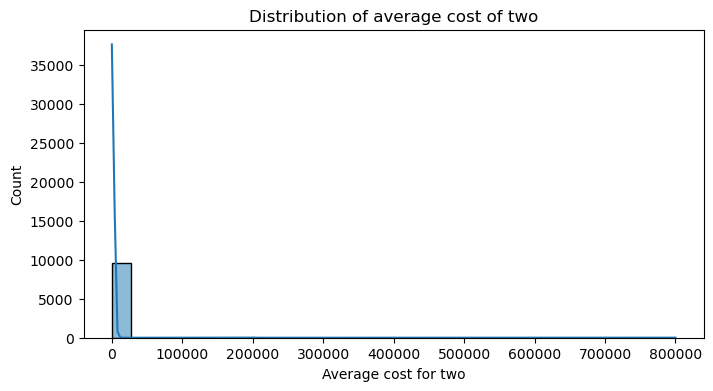

In [44]:
# Cost distribution plot

plt.figure(figsize=(8,4))
sns.histplot(data_merged['Average Cost for two'],bins=30,kde=True)
plt.title("Distribution of average cost of two")
plt.xlabel('Average cost for two')
plt.show()


##### Interpretation:

The cost distribution is right-skewed, with most restaurants concentrated in the lower-to-mid price range.

#### Rating Distribution Across Factors 

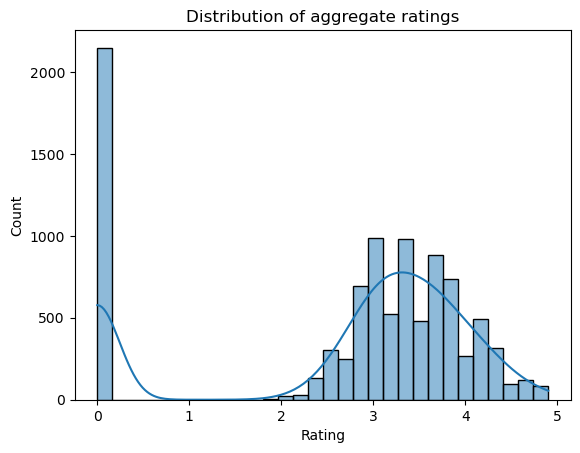

In [45]:
# overall rating 
sns.histplot(data_merged['Aggregate rating'],bins=30,kde=True)
plt.title('Distribution of aggregate ratings')
plt.xlabel('Rating')
plt.show()

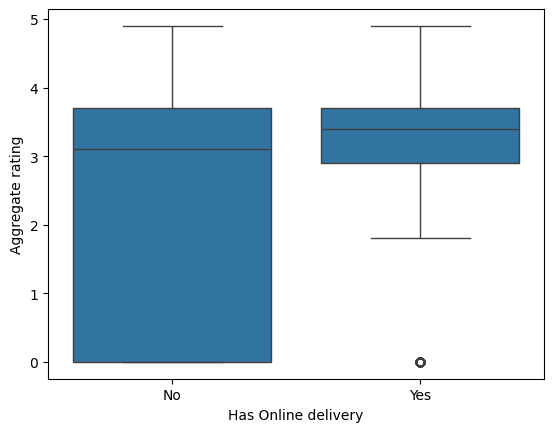

In [46]:
# rating vs online delivery

sns.boxplot(
    x='Has Online delivery',
    y='Aggregate rating',
    data=data_merged
)
plt.title='Ratings Vs Online Delivery'
plt.show()
    

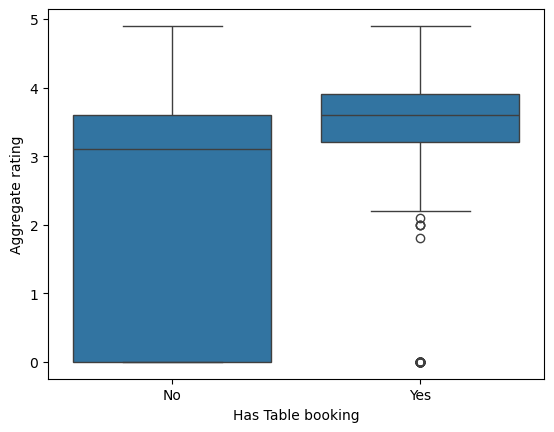

In [47]:
# rating vs table booking 

sns.boxplot(
    x='Has Table booking',
    y='Aggregate rating',
    data=data_merged
)
plt.title=('Ratings Vs Table booking')
plt.show()

#### Factors affecting Rating

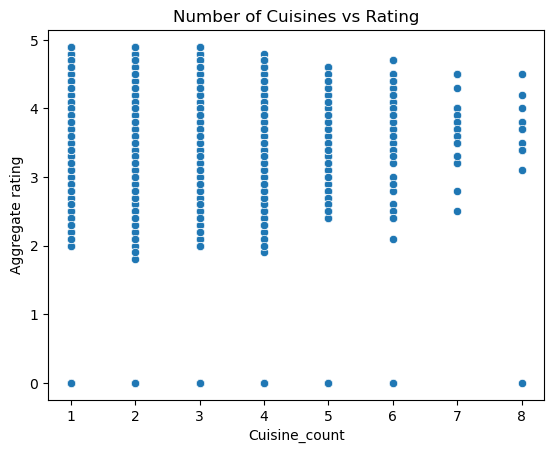

In [48]:
# Number of cuisines vs rating 

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
ax= sns.scatterplot(
    x='Cuisine_count',
    y='Aggregate rating',
    data=data_merged
)
ax. set_title("Number of Cuisines vs Rating")
plt.show()


In [49]:
data_merged.columns

Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Price range', 'Aggregate rating',
       'Rating color', 'Rating text', 'Votes', 'Country', 'Cuisine_count'],
      dtype='object')

In [50]:
type(plt.title)

str

In [51]:
import matplotlib.pyplot as plt

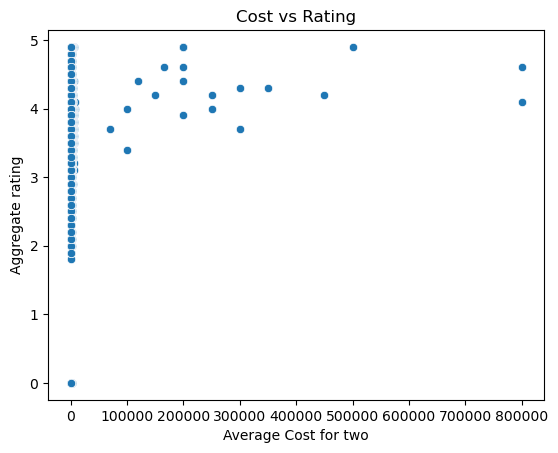

In [52]:
# Cost Vs Rating 

ay= sns.scatterplot(
    x='Average Cost for two',
    y='Aggregate rating',
    data = data_merged
)
ay.set_title("Cost vs Rating")
plt.show()

In [53]:
# Delivery option Vs Rating 
data_merged.groupby('Has Online delivery')['Aggregate rating'].mean()

Has Online delivery
No     2.465296
Yes    3.248837
Name: Aggregate rating, dtype: float64



#### Ratings appear to be influenced by multiple factors. Restaurants offering online delivery and table booking generally show higher average ratings, indicating better customer accessibility. Moderate menu variety and mid-range pricing are also associated with stronger ratings, suggesting that customers value balance over extremes.
